# Trabalho 07 — Modelagem e Avaliação de Desempenho com SPN
## Contexto 1: Servidor Web

Este notebook implementa **do zero** um simulador de Redes de Petri Estocásticas (SPN) e o usa para avaliar o desempenho de um servidor web com **fila de capacidade limitada** e **vários núcleos de processamento**.

**Pergunta de pesquisa:** como a demanda (taxa de chegada), o número de núcleos e a capacidade da fila afetam o tempo de resposta, a vazão e a probabilidade de descarte de requisições, e qual configuração equilibra recursos e desempenho?

**Estrutura do notebook**
1. Parâmetros globais e de referência
2. Motor de simulação SPN (lugares, transições temporizadas e imediatas, arcos inibidores, marcação inicial)
3. Modelo SPN do servidor web
4. Métricas de desempenho (TP, MRT, MQT, MPT, U, DP)
5. Validação contra a solução analítica M/M/c/K
6. Experimentos E1 a E4
7. Tabela consolidada e gráficos
8. Figura do modelo SPN

Tudo é reprodutível: sementes fixas, resultados salvos em `results/` e figuras em `figures/`.

## 1. Parâmetros globais e cenário de referência

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Taxa de serviço por núcleo $\mu$ | 20 req/s (tempo médio 50 ms) | ordem de grandeza de uma página dinâmica simples |
| Núcleos $c$ (referência) | 4 | servidor de pequeno porte |
| Capacidade da fila $K_q$ (referência) | 20 | backlog de conexões de espera |
| Taxa de chegada $\lambda$ (referência) | 72 req/s | carga de pico: $\rho=\lambda/(c\mu)=0{,}9$ |
| Horizonte de simulação | 400 s (aquecimento de 40 s) | cerca de 8 000 tempos médios de serviço |
| Réplicas independentes | 10 por configuração | intervalo de confiança de 95 % (t de Student) |

Chegadas e serviços são exponenciais (transições temporizadas com semântica de servidor único para a chegada e de servidor infinito para o serviço). O regime avaliado é o **estacionário**: descarta-se o período de aquecimento e analisam-se as médias no tempo da marcação.

**SLA usado na recomendação:** probabilidade de descarte $\leq 1\%$ e tempo médio de resposta $\leq 100$ ms (o dobro do tempo médio de serviço).

In [1]:
import os, math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
try:
    from IPython.display import display
except Exception:
    display = print

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

MU = 20.0                                   # req/s por núcleo (tempo médio de serviço = 50 ms)
BASE = dict(lam=72.0, c=4, kq=20)           # cenário de referência
T_END, WARMUP, REPS, SEED0 = 400.0, 40.0, 10, 2026
SLA_DP, SLA_MRT = 1.0, 100.0                # % e ms

plt.rcParams.update({"font.size": 8, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 120, "savefig.dpi": 300})

## 2. Motor de simulação SPN

Um modelo SPN é formado por **lugares** (guardam tokens), **transições** (temporizadas, com taxa exponencial, ou imediatas, com prioridade e peso) e **arcos** (de entrada, de saída e inibidores). O simulador abaixo é genérico: qualquer rede construída com `add_place` e `add_transition` pode ser simulada.

- Transição **habilitada**: todos os lugares de entrada têm tokens suficientes e todos os lugares ligados por arco inibidor têm menos tokens que o peso do arco.
- **Imediatas** disparam antes de qualquer temporizada (por prioridade e, em empate, por peso).
- **Temporizadas** competem (race policy): o próximo disparo ocorre após $\text{Exp}(\sum r_i)$, e a transição $i$ vence com probabilidade $r_i/\sum r$.
- Semântica de servidor infinito: taxa efetiva $=\,r\times$ grau de habilitação.
- Calcula-se a **média no tempo** do número de tokens de cada lugar (após o aquecimento) e a contagem de disparos de cada transição.

In [3]:
class SPN:
    """Rede de Petri Estocástica com transições temporizadas/imediatas e arcos inibidores."""
    def __init__(self, name):
        self.name, self.pidx, self.m0, self.tr = name, {}, [], []

    def add_place(self, name, tokens=0):
        self.pidx[name] = len(self.m0)
        self.m0.append(tokens)

    def add_transition(self, name, kind, inputs=(), outputs=(), inhibitors=(),
                       rate=None, infinite=False, priority=1, weight=1.0, guard=None):
        conv = lambda arcs: [(self.pidx[p], w) for p, w in arcs]
        self.tr.append(dict(id=len(self.tr), name=name, kind=kind, ins=conv(inputs),
                            outs=conv(outputs), inh=conv(inhibitors), rate=rate,
                            inf=infinite, prio=priority, w=weight, guard=guard))


def _enabled(t, m):
    for p, w in t["ins"]:
        if m[p] < w: return False
    for p, w in t["inh"]:
        if m[p] >= w: return False
    return t["guard"] is None or t["guard"](m)


def _degree(t, m):
    return min(m[p] // w for p, w in t["ins"])


def simulate(net, t_end, warmup, seed):
    """Simulação estocástica de eventos discretos de uma SPN.
    Retorna a média no tempo dos tokens por lugar e o número de disparos por transição."""
    rng = random.Random(seed)
    m = list(net.m0)
    npl = len(m)
    imm = [t for t in net.tr if t["kind"] == "imm"]
    tim = [t for t in net.tr if t["kind"] == "timed"]
    area, fires = [0.0] * npl, [0] * len(net.tr)
    now, warm = 0.0, False

    def fire(t):
        for p, w in t["ins"]:  m[p] -= w
        for p, w in t["outs"]: m[p] += w
        fires[t["id"]] += 1

    def accumulate(t0, t1):
        lo = max(t0, warmup)
        if t1 > lo:
            d = t1 - lo
            for i in range(npl): area[i] += m[i] * d

    while True:
        # 1) resolve transições imediatas (marcações evanescentes)
        for _ in range(100000):
            cand = [t for t in imm if _enabled(t, m)]
            if not cand: break
            top = max(t["prio"] for t in cand)
            cand = [t for t in cand if t["prio"] == top]
            t = cand[0] if len(cand) == 1 else rng.choices(cand, weights=[x["w"] for x in cand])[0]
            fire(t)
        # 2) transições temporizadas habilitadas e suas taxas efetivas
        en, total = [], 0.0
        for t in tim:
            if _enabled(t, m):
                r = t["rate"] * (_degree(t, m) if t["inf"] else 1)
                en.append((t, r)); total += r
        if total == 0.0:
            accumulate(now, t_end); break               # deadlock (não ocorre neste modelo)
        nxt = now + rng.expovariate(total)
        if nxt > t_end:
            accumulate(now, t_end); break
        accumulate(now, nxt)
        if not warm and nxt >= warmup:
            warm, fires[:] = True, [0] * len(fires)     # zera contadores ao fim do aquecimento
        u, acc = rng.random() * total, 0.0
        for t, r in en:
            acc += r
            if u <= acc: break
        fire(t)
        now = nxt

    T = t_end - warmup
    return dict(T=T,
                mean={p: area[i] / T for p, i in net.pidx.items()},
                fires={t["name"]: fires[t["id"]] for t in net.tr})

## 3. Modelo SPN do servidor web

**Lugares**

| Lugar | Marcação inicial | Significado |
|---|---|---|
| `P_Chegada` | 1 | fonte de requisições (clientes) |
| `P_Req` | 0 | requisição recém-chegada aguardando decisão de admissão |
| `P_Vagas` | $K_q$ | vagas livres na fila de espera |
| `P_Fila` | 0 | requisições esperando por um núcleo |
| `P_Servidores` | $c$ | núcleos livres |
| `P_Proc` | 0 | requisições em processamento |
| `P_Concluidas` | 0 | contador de requisições atendidas |
| `P_Descartadas` | 0 | contador de requisições descartadas |

**Transições**

| Transição | Tipo | Parâmetro | Entradas → Saídas |
|---|---|---|---|
| `T_Chegada` | temporizada | taxa $\lambda$ | `P_Chegada` → `P_Chegada`, `P_Req` |
| `T_Admite` | imediata | peso 1 | `P_Req`, `P_Vagas` → `P_Fila` |
| `T_Descarta` | imediata | **arco inibidor** de `P_Vagas` | `P_Req` → `P_Descartadas` |
| `T_Inicio` | imediata | peso 1 | `P_Fila`, `P_Servidores` → `P_Proc`, `P_Vagas` |
| `T_Servico` | temporizada, servidor infinito | taxa $\mu$ por token | `P_Proc` → `P_Servidores`, `P_Concluidas` |

O arco inibidor `P_Vagas` → `T_Descarta` faz a requisição ser descartada somente quando não há vaga na fila (`#P_Vagas = 0`). A capacidade total do sistema é $K=c+K_q$, de modo que o modelo corresponde a uma fila M/M/c/K.

In [4]:
def build_net(lam, mu, c, kq):
    n = SPN("Servidor Web")
    n.add_place("P_Chegada", 1)
    n.add_place("P_Req", 0)
    n.add_place("P_Vagas", kq)
    n.add_place("P_Fila", 0)
    n.add_place("P_Servidores", c)
    n.add_place("P_Proc", 0)
    n.add_place("P_Concluidas", 0)
    n.add_place("P_Descartadas", 0)

    n.add_transition("T_Chegada", "timed", inputs=[("P_Chegada", 1)],
                     outputs=[("P_Chegada", 1), ("P_Req", 1)], rate=lam)
    n.add_transition("T_Admite", "imm", inputs=[("P_Req", 1), ("P_Vagas", 1)],
                     outputs=[("P_Fila", 1)])
    n.add_transition("T_Descarta", "imm", inputs=[("P_Req", 1)],
                     inhibitors=[("P_Vagas", 1)], outputs=[("P_Descartadas", 1)])
    n.add_transition("T_Inicio", "imm", inputs=[("P_Fila", 1), ("P_Servidores", 1)],
                     outputs=[("P_Proc", 1), ("P_Vagas", 1)])
    n.add_transition("T_Servico", "timed", inputs=[("P_Proc", 1)],
                     outputs=[("P_Servidores", 1), ("P_Concluidas", 1)],
                     rate=mu, infinite=True)
    return n

## 4. Métricas de desempenho

Todas as métricas são expressas em função do modelo SPN. Seja $E\{\#P\}$ o número esperado de tokens no lugar $P$ (média no tempo no regime estacionário), $N(T)$ o número de disparos da transição $T$ e $\Delta$ o intervalo observado.

| Métrica | Expressão | Unidade |
|---|---|---|
| Throughput (TP) | $N(\texttt{T\_Servico})/\Delta$ | req/s |
| Utilização (U) | $E\{\#\texttt{P\_Proc}\}/c \times 100$ | % |
| Drop Probability (DP) | $N(\texttt{T\_Descarta})/N(\texttt{T\_Chegada}) \times 100$ | % |
| Mean Queue Time (MQT) | $E\{\#\texttt{P\_Fila}\}/\text{TP}$ | ms |
| Mean Processing Time (MPT) | $E\{\#\texttt{P\_Proc}\}/\text{TP}$ | ms |
| Mean Response Time (MRT) | $\big(E\{\#\texttt{P\_Fila}\}+E\{\#\texttt{P\_Proc}\}\big)/\text{TP}$ | ms |

MQT, MPT e MRT vêm da **Lei de Little** ($L=\lambda_{ef}\,W$) aplicada ao número médio de tokens em cada região do modelo, usando a vazão efetiva (TP).

In [5]:
KEYS = ["TP", "MRT", "MQT", "MPT", "U", "DP"]

def metrics_from_sim(res, c):
    T, L, F = res["T"], res["mean"], res["fires"]
    tp = F["T_Servico"] / T
    eq, ep = L["P_Fila"], L["P_Proc"]
    return dict(TP=tp,
                MRT=(eq + ep) / tp * 1000, MQT=eq / tp * 1000, MPT=ep / tp * 1000,
                U=100 * ep / c, DP=100 * F["T_Descarta"] / F["T_Chegada"])


def metrics_analytic(lam, mu, c, kq):
    """Solução analítica exata da fila M/M/c/K (K = c + kq)."""
    K, a = c + kq, lam / mu
    w = np.array([a**n / math.factorial(n) if n <= c
                  else a**c / math.factorial(c) * (a / c)**(n - c) for n in range(K + 1)])
    p = w / w.sum()
    n = np.arange(K + 1)
    lam_ef = lam * (1 - p[K])
    L, Lq = (n * p).sum(), (np.maximum(n - c, 0) * p).sum()
    Lp = L - Lq
    return dict(TP=lam_ef, MRT=L / lam_ef * 1000, MQT=Lq / lam_ef * 1000,
                MPT=Lp / lam_ef * 1000, U=100 * Lp / c, DP=100 * p[K])

## 5. Validação do modelo

Antes de usar o simulador nos experimentos, compara-se a SPN com a solução analítica exata da fila M/M/c/K nas mesmas condições. Considera-se que o valor simulado **concorda** com o analítico quando a diferença é menor que o IC de 95 % (ou menor que 0,05, tolerância absoluta para valores praticamente nulos ou em saturação). Se as médias simuladas coincidirem com os valores analíticos, o modelo e o simulador estão corretos.

In [6]:
def run_config(lam, c, kq, reps=REPS):
    """Executa `reps` réplicas independentes e retorna médias, IC95% e valores analíticos."""
    net = build_net(lam, MU, c, kq)
    samples = {k: [] for k in KEYS}
    raw = []
    for r in range(reps):
        seed = SEED0 + 7919 * r + int(lam * 10) * 31 + c * 131 + kq * 17
        m = metrics_from_sim(simulate(net, T_END, WARMUP, seed), c)
        for k in KEYS: samples[k].append(m[k])
        raw.append(dict(lam=lam, c=c, kq=kq, rep=r, seed=seed, **m))
    ana = metrics_analytic(lam, MU, c, kq)
    row = dict(lam=lam, c=c, kq=kq, rho=lam / (c * MU))
    tcrit = stats.t.ppf(0.975, reps - 1)
    for k in KEYS:
        x = np.array(samples[k])
        row[k] = x.mean()
        row[k + "_ci"] = tcrit * x.std(ddof=1) / math.sqrt(reps)
        row[k + "_ana"] = ana[k]
    return row, raw

_cache, RAW = {}, []
def get(lam, c, kq):
    key = (lam, c, kq)
    if key not in _cache:
        _cache[key], raw = run_config(lam, c, kq)
        RAW.extend(raw)
    return _cache[key]

t0 = time.time()
val = pd.DataFrame([get(*cfg) for cfg in [(24.0, 4, 20), (72.0, 4, 20), (120.0, 4, 20)]])
rows = []
for _, r in val.iterrows():
    for k in ["TP", "MRT", "U", "DP"]:
        rows.append(dict(lam=r.lam, metrica=k, simulado=r[k], ic95=r[k + "_ci"], analitico=r[k + "_ana"],
                         erro_rel_pct=100 * abs(r[k] - r[k + "_ana"]) / max(abs(r[k + "_ana"]), 1e-9),
                         concorda=abs(r[k] - r[k + "_ana"]) <= max(r[k + "_ci"], 0.05)))
validacao = pd.DataFrame(rows)
validacao.to_csv("results/validacao_mmck.csv", index=False)
display(validacao.round(3))
print(f"Tempo de validação: {time.time()-t0:.0f} s")

,lam,metrica,simulado,ic95,analitico,erro_rel_pct,concorda
0,24.0,TP,24.153,0.181,24.000,0.637,True
1,24.0,MRT,50.674,0.305,50.662,0.024,True
2,24.0,U,30.171,0.224,30.000,0.571,True
3,24.0,DP,0.000,0.000,0.000,9.043,True
4,72.0,TP,71.408,0.199,71.245,0.229,True
5,72.0,MRT,120.339,2.823,119.180,0.972,True
6,72.0,U,89.056,0.398,89.057,0.000,True
7,72.0,DP,1.118,0.193,1.048,6.653,True
8,120.0,TP,80.216,0.331,79.997,0.274,True
9,120.0,MRT,274.583,1.343,275.037,0.165,True


Tempo de validação: 23 s


## 6. Planejamento experimental

O **cenário de referência** é $\lambda=72$ req/s, $c=4$ núcleos e $K_q=20$ ($\rho=0{,}9$). Em cada conjunto de experimentos varia-se apenas o parâmetro indicado, mantendo os demais constantes.

| Conjunto | Parâmetro variado | Valores |
|---|---|---|
| E1 | taxa de chegada $\lambda$ (5 níveis) | 24, 48, 72, 96, 120 req/s ($\rho$ = 0,3 a 1,5) |
| E2 | núcleos $c$ (3 configurações) | 3, 4, 5 |
| E3 | capacidade da fila $K_q$ (3 limites) | 5, 20, 80 |
| E4 | demanda e recursos combinados (3 cenários, todos com $\rho=0{,}8$) | S1: 48 req/s, 3 núcleos, $K_q=10$; S2: 96 req/s, 6 núcleos, $K_q=20$; S3: 192 req/s, 12 núcleos, $K_q=40$ |

In [7]:
E1 = [get(l, BASE["c"], BASE["kq"]) for l in (24.0, 48.0, 72.0, 96.0, 120.0)]
E2 = [get(BASE["lam"], c, BASE["kq"]) for c in (3, 4, 5)]
E3 = [get(BASE["lam"], BASE["c"], k) for k in (5, 20, 80)]
E4_cfg = [("S1", 48.0, 3, 10), ("S2", 96.0, 6, 20), ("S3", 192.0, 12, 40)]
E4 = [get(l, c, k) for _, l, c, k in E4_cfg]

def sla_ok(r): return (r["DP"] <= SLA_DP) and (r["MRT"] <= SLA_MRT)

def to_df(exp, rows, labels):
    out = []
    for lab, r in zip(labels, rows):
        d = dict(Exp=exp, Cenario=lab, lam=r["lam"], c=r["c"], Kq=r["kq"], rho=round(r["rho"], 2))
        for k in KEYS:
            d[k] = r[k]; d[k + "_ic95"] = r[k + "_ci"]; d[k + "_analitico"] = r[k + "_ana"]
        d["SLA"] = sla_ok(r)
        out.append(d)
    return pd.DataFrame(out)

df1 = to_df("E1", E1, [f"lam={r['lam']:.0f}" for r in E1])
df2 = to_df("E2", E2, [f"c={r['c']}" for r in E2])
df3 = to_df("E3", E3, [f"Kq={r['kq']}" for r in E3])
df4 = to_df("E4", E4, [n for n, *_ in E4_cfg])
for name, d in zip(["e1_demanda", "e2_nucleos", "e3_fila", "e4_combinado"], [df1, df2, df3, df4]):
    d.to_csv(f"results/{name}.csv", index=False)
pd.DataFrame(RAW).to_csv("results/replicacoes_brutas.csv", index=False)
print(f"Experimentos concluídos ({len(_cache)} configurações x {REPS} réplicas).")

Experimentos concluídos (12 configurações x 10 réplicas).


## 7. Tabela consolidada de parâmetros e resultados

Valores: média das réplicas. A coluna **SLA** indica se a configuração atende DP $\leq 1\%$ e MRT $\leq 100$ ms.

In [8]:
cons = pd.concat([df1, df2, df3, df4], ignore_index=True)
tab = cons[["Exp", "Cenario", "lam", "c", "Kq", "rho", "TP", "MRT", "MQT", "MPT", "U", "DP", "SLA"]].copy()
tab.to_csv("results/tabela_consolidada.csv", index=False)
display(tab.round(2))

def latex_table(df):
    L = []
    for _, r in df.iterrows():
        L.append(f"{r.Exp} & {r.lam:.0f} & {r.c} & {r.Kq} & {r.rho:.2f} & {r.TP:.1f} & {r.MRT:.0f} & "
                 f"{r.MQT:.0f} & {r.U:.1f} & {r.DP:.2f} & {'Sim' if r.SLA else 'Não'} \\\\")
    return "\n".join(L)
open("results/tabela_consolidada_linhas.tex", "w").write(latex_table(tab))

,Exp,Cenario,lam,c,Kq,rho,TP,MRT,MQT,MPT,U,DP,SLA
0,E1,lam=24,24.0,4,20,0.30,24.15,50.67,0.70,49.97,30.17,0.00,True
1,E1,lam=48,48.0,4,20,0.60,48.22,58.88,9.04,49.84,60.08,0.00,True
2,E1,lam=72,72.0,4,20,0.90,71.41,120.34,70.45,49.89,89.06,1.12,False
3,E1,lam=96,96.0,4,20,1.20,79.90,241.61,191.72,49.89,99.66,16.67,False
4,E1,lam=120,120.0,4,20,1.50,80.22,274.58,224.72,49.87,100.00,33.34,False
5,E2,c=3,72.0,3,20,1.20,59.58,308.71,258.52,50.19,99.68,17.29,False
6,E2,c=4,72.0,4,20,0.90,71.41,120.34,70.45,49.89,89.06,1.12,False
7,E2,c=5,72.0,5,20,0.72,71.80,64.21,14.35,49.85,71.59,0.02,True
8,E3,Kq=5,72.0,4,5,0.90,66.54,70.80,20.97,49.82,82.88,7.93,False
9,E3,Kq=20,72.0,4,20,0.90,71.41,120.34,70.45,49.89,89.06,1.12,False


910

## 8. Gráficos

Todos os gráficos têm eixos nomeados com unidade e legenda. Pontos com barras de erro são a média simulada com IC de 95 %; as linhas tracejadas são a solução analítica M/M/c/K.

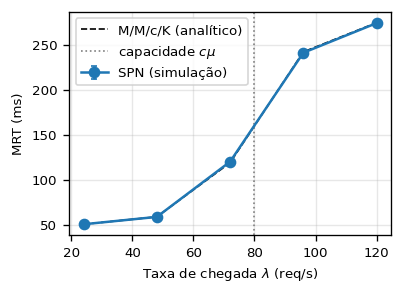

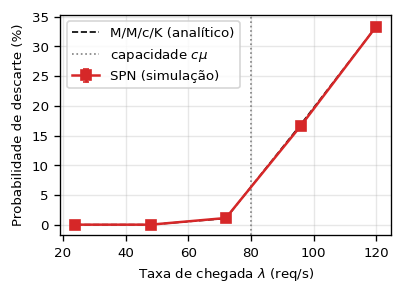

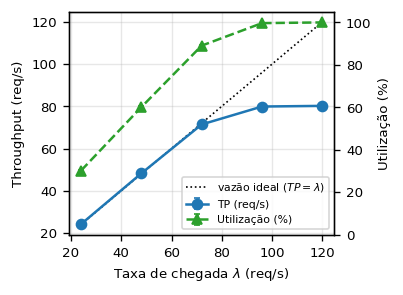

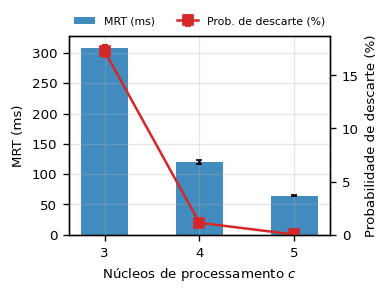

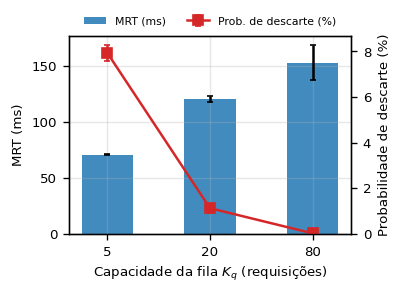

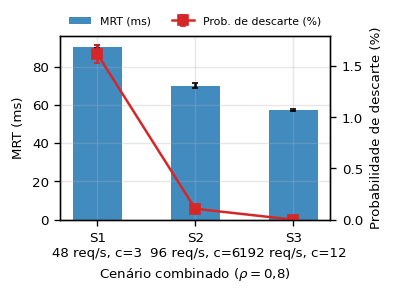

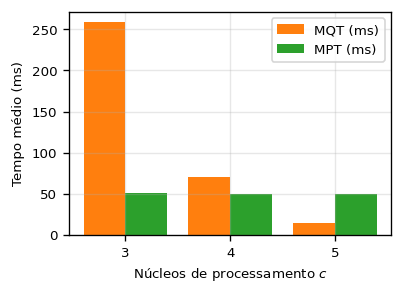

In [9]:
MARK = ["o", "s", "^", "D"]
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png"); fig.savefig(f"figures/{name}.pdf")
    plt.show()

def cap_line(ax, lam_cap):
    ax.axvline(lam_cap, color="gray", ls=":", lw=1, label=r"capacidade $c\mu$")

x1 = [r["lam"] for r in E1]
cap = BASE["c"] * MU

# G1 - MRT x demanda
fig, ax = plt.subplots(figsize=(3.4, 2.5))
ax.errorbar(x1, [r["MRT"] for r in E1], yerr=[r["MRT_ci"] for r in E1], fmt="o-", capsize=2, label="SPN (simulação)")
ax.plot(x1, [r["MRT_ana"] for r in E1], "k--", lw=1, label="M/M/c/K (analítico)")
cap_line(ax, cap)
ax.set_xlabel("Taxa de chegada $\\lambda$ (req/s)"); ax.set_ylabel("MRT (ms)"); ax.legend()
save(fig, "g1_e1_mrt")

# G2 - DP x demanda
fig, ax = plt.subplots(figsize=(3.4, 2.5))
ax.errorbar(x1, [r["DP"] for r in E1], yerr=[r["DP_ci"] for r in E1], fmt="s-", color="C3", capsize=2, label="SPN (simulação)")
ax.plot(x1, [r["DP_ana"] for r in E1], "k--", lw=1, label="M/M/c/K (analítico)")
cap_line(ax, cap)
ax.set_xlabel("Taxa de chegada $\\lambda$ (req/s)"); ax.set_ylabel("Probabilidade de descarte (%)"); ax.legend()
save(fig, "g2_e1_dp")

# G3 - TP e U x demanda
fig, ax = plt.subplots(figsize=(3.4, 2.5))
ax.plot(x1, x1, "k:", lw=1, label="vazão ideal ($TP=\\lambda$)")
ax.errorbar(x1, [r["TP"] for r in E1], yerr=[r["TP_ci"] for r in E1], fmt="o-", capsize=2, label="TP (req/s)")
ax.set_xlabel("Taxa de chegada $\\lambda$ (req/s)"); ax.set_ylabel("Throughput (req/s)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.errorbar(x1, [r["U"] for r in E1], yerr=[r["U_ci"] for r in E1], fmt="^--", color="C2", capsize=2, label="Utilização (%)")
ax2.set_ylabel("Utilização (%)"); ax2.set_ylim(0, 105)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=6.5)
save(fig, "g3_e1_tp_util")

def bars_twin(rows, labels, xlabel, name):
    fig, ax = plt.subplots(figsize=(3.4, 2.5))
    x = np.arange(len(rows))
    ax.bar(x, [r["MRT"] for r in rows], 0.5, yerr=[r["MRT_ci"] for r in rows], capsize=2,
           color="C0", alpha=0.85, label="MRT (ms)")
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_xlabel(xlabel); ax.set_ylabel("MRT (ms)")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.errorbar(x, [r["DP"] for r in rows], yerr=[r["DP_ci"] for r in rows], fmt="s-", color="C3",
                 capsize=2, label="Prob. de descarte (%)")
    ax2.set_ylabel("Probabilidade de descarte (%)"); ax2.set_ylim(bottom=0)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=6.5, frameon=False)
    save(fig, name)

bars_twin(E2, [f"{r['c']}" for r in E2], "Núcleos de processamento $c$", "g4_e2_nucleos")
bars_twin(E3, [f"{r['kq']}" for r in E3], "Capacidade da fila $K_q$ (requisições)", "g5_e3_fila")
bars_twin(E4, [f"{n}\n{int(l)} req/s, c={c}" for (n, l, c, k) in E4_cfg], "Cenário combinado ($\\rho=0{,}8$)", "g6_e4_combinado")

# G7 - Utilização e MQT por número de núcleos (gargalo)
fig, ax = plt.subplots(figsize=(3.4, 2.5))
x = np.arange(len(E2))
ax.bar(x - 0.2, [r["MQT"] for r in E2], 0.4, label="MQT (ms)", color="C1")
ax.bar(x + 0.2, [r["MPT"] for r in E2], 0.4, label="MPT (ms)", color="C2")
ax.set_xticks(x); ax.set_xticklabels([f"{r['c']}" for r in E2]); ax.set_xlabel("Núcleos de processamento $c$")
ax.set_ylabel("Tempo médio (ms)"); ax.legend(loc="upper right")
save(fig, "g7_e2_mqt_mpt")

## 9. Figura do modelo SPN

Círculos são lugares, retângulos brancos são transições temporizadas, barras pretas são transições imediatas e o arco com círculo vazado é o arco inibidor.

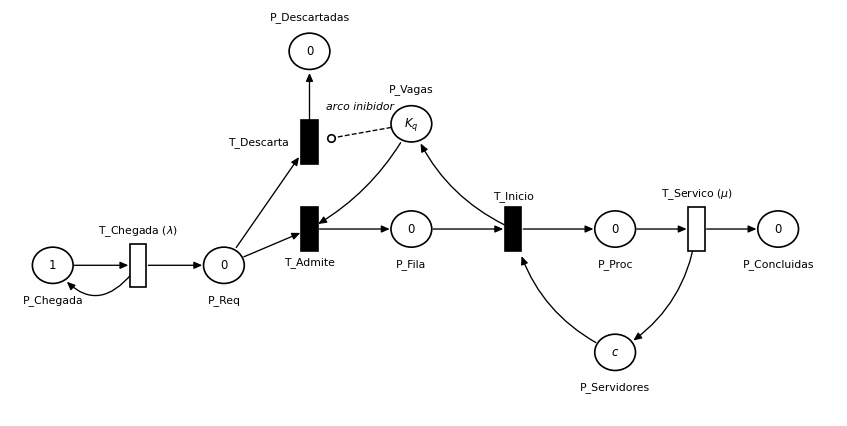

In [10]:
def draw_spn(name="fig_modelo_spn"):
    fig, ax = plt.subplots(figsize=(7.1, 3.6))
    ax.set_xlim(-1, 19.2); ax.set_ylim(-3.6, 7.3); ax.axis("off"); ax.grid(False)
    R = 0.5
    def label(x, y, txt, pos):
        kw = dict(fontsize=6.5)
        if pos == "below": ax.text(x, y - 0.8, txt, ha="center", va="top", **kw)
        elif pos == "above": ax.text(x, y + 0.8, txt, ha="center", va="bottom", **kw)
        elif pos == "left": ax.text(x - 0.5, y, txt, ha="right", va="center", **kw)
    def place(x, y, lab, tok, pos="below"):
        ax.add_patch(plt.Circle((x, y), R, fc="white", ec="k", lw=1, zorder=3))
        ax.text(x, y, tok, ha="center", va="center", fontsize=7, zorder=4)
        label(x, y, lab, pos)
    def trans(x, y, lab, timed, pos="below"):
        ax.add_patch(plt.Rectangle((x - 0.2, y - 0.6), 0.4, 1.2, fc="white" if timed else "k", ec="k", lw=1, zorder=3))
        label(x, y + (-0.0 if pos != "below" else -0.0), lab, pos) if pos == "left" else \
            ax.text(x, y + (0.75 if pos == "above" else -0.75), lab, ha="center",
                    va="bottom" if pos == "above" else "top", fontsize=6.5)
    def arc(a, b, rad=0.0, sa=13, sb=13):
        ax.annotate("", xy=b, xytext=a, zorder=2,
                    arrowprops=dict(arrowstyle="-|>,head_length=0.5,head_width=0.22", lw=0.8,
                                    shrinkA=sa, shrinkB=sb, connectionstyle=f"arc3,rad={rad}", color="k"))
    PL, TR = 13, 6          # recuos (pt) para lugar e transição
    P = dict(cheg=(0, 0.5), req=(4.2, 0.5), vagas=(8.8, 4.4), fila=(8.8, 1.5), serv=(13.8, -1.9),
             proc=(13.8, 1.5), conc=(17.8, 1.5), desc=(6.3, 6.4))
    T = dict(tc=(2.1, 0.5), ta=(6.3, 1.5), td=(6.3, 3.9), ti=(11.3, 1.5), ts=(15.8, 1.5))
    place(*P["cheg"], "P_Chegada", "1"); place(*P["req"], "P_Req", "0")
    place(*P["vagas"], "P_Vagas", "$K_q$", "above"); place(*P["fila"], "P_Fila", "0", "below")
    place(*P["serv"], "P_Servidores", "$c$"); place(*P["proc"], "P_Proc", "0", "below")
    place(*P["conc"], "P_Concluidas", "0", "below"); place(*P["desc"], "P_Descartadas", "0", "above")
    trans(*T["tc"], r"T_Chegada ($\lambda$)", True, "above"); trans(*T["ta"], "T_Admite", False, "below")
    trans(*T["td"], "T_Descarta", False, "left"); trans(*T["ti"], "T_Inicio", False, "above")
    trans(*T["ts"], r"T_Servico ($\mu$)", True, "above")
    arc(P["cheg"], T["tc"], sa=PL, sb=TR); arc(T["tc"], P["req"], sa=TR, sb=PL)
    arc(T["tc"], P["cheg"], rad=-0.7, sa=TR, sb=PL)
    arc(P["req"], T["ta"], sa=PL, sb=TR); arc(P["req"], T["td"], sa=PL, sb=11)
    arc(T["ta"], P["fila"], sa=TR, sb=PL); arc(T["td"], P["desc"], sa=TR, sb=PL)
    arc(P["vagas"], T["ta"], rad=-0.15, sa=PL, sb=TR)
    arc(T["ti"], P["vagas"], rad=-0.2, sa=TR, sb=PL)
    arc(P["fila"], T["ti"], sa=PL, sb=TR); arc(T["ti"], P["proc"], sa=TR, sb=PL)
    arc(P["proc"], T["ts"], sa=PL, sb=TR); arc(T["ts"], P["conc"], sa=TR, sb=PL)
    arc(T["ts"], P["serv"], rad=-0.25, sa=TR, sb=PL); arc(P["serv"], T["ti"], rad=-0.25, sa=PL, sb=17)
    # arco inibidor P_Vagas -> T_Descarta (ponta com círculo vazado)
    a, b = np.array(P["vagas"]), np.array(T["td"])
    d = (a - b) / np.linalg.norm(a - b)
    p0, p1 = a - d * R, b + d * 0.55
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color="k", lw=0.8, ls="--", zorder=1)
    ax.plot(*p1, "o", mfc="white", mec="k", ms=4.5, zorder=4)
    ax.text(7.55, 4.75, "arco inibidor", fontsize=6.5, style="italic", ha="center", va="bottom")
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png"); fig.savefig(f"figures/{name}.pdf")
    plt.show()

draw_spn()

## 10. Resumo para a discussão (gerado a partir dos resultados)

In [11]:
base = get(BASE["lam"], BASE["c"], BASE["kq"])
print("Referência (lambda=72, c=4, Kq=20): "
      f"TP={base['TP']:.1f} req/s, MRT={base['MRT']:.0f} ms, MQT={base['MQT']:.0f} ms, "
      f"U={base['U']:.1f}%, DP={base['DP']:.2f}%")
print()
print("Configurações que atendem o SLA (DP <= 1% e MRT <= 100 ms):")
display(tab[tab.SLA][["Exp", "Cenario", "lam", "c", "Kq", "MRT", "DP", "U"]].round(2))
print("Configurações que NÃO atendem:")
display(tab[~tab.SLA][["Exp", "Cenario", "lam", "c", "Kq", "MRT", "DP", "U"]].round(2))

Referência (lambda=72, c=4, Kq=20): TP=71.4 req/s, MRT=120 ms, MQT=70 ms, U=89.1%, DP=1.12%

Configurações que atendem o SLA (DP <= 1% e MRT <= 100 ms):


,Exp,Cenario,lam,c,Kq,MRT,DP,U
0,E1,lam=24,24.0,4,20,50.67,0.00,30.17
1,E1,lam=48,48.0,4,20,58.88,0.00,60.08
7,E2,c=5,72.0,5,20,64.21,0.02,71.59
12,E4,S2,96.0,6,20,70.07,0.11,79.69
13,E4,S3,192.0,12,40,57.44,0.00,79.99


Configurações que NÃO atendem:


,Exp,Cenario,lam,c,Kq,MRT,DP,U
2,E1,lam=72,72.0,4,20,120.34,1.12,89.06
3,E1,lam=96,96.0,4,20,241.61,16.67,99.66
4,E1,lam=120,120.0,4,20,274.58,33.34,100.00
5,E2,c=3,72.0,3,20,308.71,17.29,99.68
6,E2,c=4,72.0,4,20,120.34,1.12,89.06
8,E3,Kq=5,72.0,4,5,70.80,7.93,82.88
9,E3,Kq=20,72.0,4,20,120.34,1.12,89.06
10,E3,Kq=80,72.0,4,80,152.92,0.01,90.09
11,E4,S1,48.0,3,10,90.59,1.62,79.32
